# Projeto 4 — Análise Preditiva e Interpretação de Churn em Telecomunicações (Telco Customer Churn)

**Disciplina:** Introdução à Ciência de Dados (ICMC-USP)  
**Objetivo:** Desenvolver e comparar modelos supervisionados para prever o cancelamento de clientes (*churn*), avaliar estratégias de tratamento de desbalanceamento sob protocolo livre de vazamento de dados (*data leakage*), analisar o impacto operacional do limiar de decisão e discutir os principais fatores associados ao risco de evasão com foco em tomada de decisão orientada a retenção.

---

### Estrutura do Projeto
1. **Preparação e Limpeza dos Dados** — Auditoria de tipos, valores ausentes ocultos em `TotalCharges`, duplicatas e exclusão justificada de `customerID`.
2. **Análise Exploratória de Dados (EDA)** — Proporção global de *churn*, estatísticas descritivas, distribuição de contratos, serviços, formas de pagamento, cobranças e correlações numéricas.
3. **Seleção, Redundâncias, Engenharia de Atributos e Divisão Estratificada** — *Split* 80/20 estratificado prévio, diagnóstico de redundâncias estruturais e colinearidade (VIF) e teste empírico em validação cruzada (CV).
4. **Modelagem e Ajuste de Hiperparâmetros (CV sem Vazamento)** — `LogisticRegression`, `RandomForest` e `XGBoost` encapsulados em `ImbPipeline` com `GridSearchCV` (`StratifiedKFold`).
5. **Estratégias de Balanceamento** — Comparação controlada entre base original, ponderação de classes (`class_weight` / `scale_pos_weight`), *oversampling* (`SMOTE`) e *undersampling* (`RandomUnderSampler`).
6. **Avaliação no Conjunto de Teste, Limiar de Decisão e Campanha Top 10%** — Matriz de confusão, Precision, Recall, F1, ROC-AUC, Average Precision, curvas ROC/PR e simulação de retenção.
7. **Interpretação e Consistência entre Modelos** — Comparação de importâncias entre os três algoritmos.
8. **Discussão Crítica** — Respostas às questões norteadoras, associação estatística vs. causalidade e limitações.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from IPython.display import display
except ImportError:
    display = print

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler

RANDOM_STATE = 42
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", None)

## 1. Preparação e Limpeza dos Dados

O conjunto *Telco Customer Churn* reúne **7.043 clientes** e **21 colunas** originais (identificador, características demográficas, tempo de permanência, serviços contratados, faturamento e a variável-alvo `Churn`).

Nesta etapa realizamos:
- Conversão explícita de `TotalCharges` para formato numérico (`float`), revelando **11 registros** armazenados no CSV como strings de espaço em branco (`" "`);
- Verificação de que 100% desses 11 clientes possuem **`tenure == 0`** (clientes recém-ingressados antes do fechamento da primeira fatura acumulada), o que fundamenta a imputação exata de `TotalCharges = 0.0` sem descarte de observações;
- Verificação de registros duplicados exatos e criação da variável-alvo binária (`Churn_Binario`: `Yes -> 1`, `No -> 0`);
- Exclusão justificada de **`customerID`**, pois trata-se de identificador único arbitrário (7.043 categorias distintas) sem poder de generalização para novos clientes e que provocaria sobreajuste extremo ou explosão dimensional se codificado.

In [2]:
GITHUB_URL = (
    "https://raw.githubusercontent.com/IBM/"
    "telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
)

try:
    df_raw = pd.read_csv(GITHUB_URL)
except Exception:
    # alternativa: arquivo do Kaggle salvo localmente na mesma pasta do notebook
    df_raw = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(f"Dimensão original: {df_raw.shape[0]} linhas x {df_raw.shape[1]} colunas")
print("\nTipos originais das colunas:")
print(df_raw.dtypes)

df = df_raw.copy()
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

auditoria_nulos = pd.DataFrame({
    "nulos": df.isna().sum(),
    "percentual_%": (df.isna().sum() / len(df) * 100).round(4),
})
print("\nColunas com valores ausentes após conversão numérica de TotalCharges:")
display(auditoria_nulos[auditoria_nulos["nulos"] > 0])

print(f"Registros duplicados exatos: {df.duplicated().sum()}")
print(f"Valores únicos de customerID: {df['customerID'].nunique()} (em {len(df)} linhas)")

linhas_nulas = df[df["TotalCharges"].isna()][
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Contract", "Churn"]
]
print("\nRegistros com TotalCharges originalmente em branco (todos com tenure == 0):")
display(linhas_nulas)
assert (linhas_nulas["tenure"] == 0).all()

# Imputação semanticamente consistente: tenure == 0 => cobrança acumulada inicial = 0.0
df["TotalCharges"] = df["TotalCharges"].fillna(0.0)
df["Churn_Binario"] = df["Churn"].map({"Yes": 1, "No": 0})
df["SeniorCitizen_Label"] = df["SeniorCitizen"].map({1: "Yes", 0: "No"})

assert df.isna().sum().sum() == 0, "Ainda existem valores ausentes!"
display(df.head())

Dimensão original: 7043 linhas x 21 colunas

Tipos originais das colunas:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

Colunas com valores ausentes após conversão numérica de TotalCharges:


,nulos,percentual_%
TotalCharges,11,0.1562


Registros duplicados exatos: 0
Valores únicos de customerID: 7043 (em 7043 linhas)

Registros com TotalCharges originalmente em branco (todos com tenure == 0):


,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,4472-LVYGI,0,52.55,NaN,Two year,No
753,3115-CZMZD,0,20.25,NaN,Two year,No
936,5709-LVOEQ,0,80.85,NaN,Two year,No
1082,4367-NUYAO,0,25.75,NaN,Two year,No
1340,1371-DWPAZ,0,56.05,NaN,Two year,No
3331,7644-OMVMY,0,19.85,NaN,Two year,No
3826,3213-VVOLG,0,25.35,NaN,Two year,No
4380,2520-SGTTA,0,20.00,NaN,Two year,No
5218,2923-ARZLG,0,19.70,NaN,One year,No
6670,4075-WKNIU,0,73.35,NaN,Two year,No


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Churn_Binario,SeniorCitizen_Label
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No,0,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,No
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,0,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,No


## 2. Análise Exploratória de Dados (EDA)

A análise descritiva orienta a formulação de hipóteses antes da modelagem:
- **Desbalanceamento da classe alvo:** cerca de **73,46%** (`5.174`) dos clientes permaneceram ativos (`No`) e **26,54%** (`1.869`) cancelaram (`Yes`), caracterizando desbalanceamento moderado no qual acurácia bruta pode mascarar baixa captura da classe minoritária.
- **Variáveis numéricas:** clientes que cancelam apresentam mediana de `tenure` muito menor (`10` meses contra `38` meses dos retidos) e mediana de `MonthlyCharges` mais elevada (`79,65` contra `64,43`). Como `TotalCharges ≈ tenure × MonthlyCharges`, sua correlação marginal com `Churn` é negativa (`-0,1983`), refletindo o efeito dominante do menor tempo de permanência entre quem evade.
- **Segmentos contratuais e operacionais:** contratos mensais (`Month-to-month`), internet em fibra óptica (`Fiber optic`), pagamento via cheque eletrônico (`Electronic check`) e ausência de serviços de suporte/segurança (`TechSupport = No`, `OnlineSecurity = No`) concentram as maiores taxas relativas de cancelamento.

In [3]:
# 2.1 Proporção global do alvo
tabela_alvo = pd.DataFrame({
    "contagem": df["Churn"].value_counts(),
    "percentual_%": (df["Churn"].value_counts(normalize=True) * 100).round(2),
})
print("Distribuição Global de Churn:")
display(tabela_alvo)

Distribuição Global de Churn:


,contagem,percentual_%
Churn,,
No,5174,73.46
Yes,1869,26.54



Estatísticas numéricas segmentadas por Churn:


tenure                              MonthlyCharges                       \
       count   mean median    std min max          count   mean median    std   
Churn                                                                           
No      5174  37.57   38.0  24.11   0  72           5174  61.27  64.43  31.09   
Yes     1869  17.98   10.0  19.53   1  72           1869  74.44  79.65  24.67   

                     TotalCharges                                             
         min     max        count     mean   median      std    min      max  
Churn                                                                         
No     18.25  118.75         5174  2549.91  1679.52  2329.95   0.00  8672.45  
Yes    18.85  118.35         1869  1531.80   703.55  1890.82  18.85  8684.80

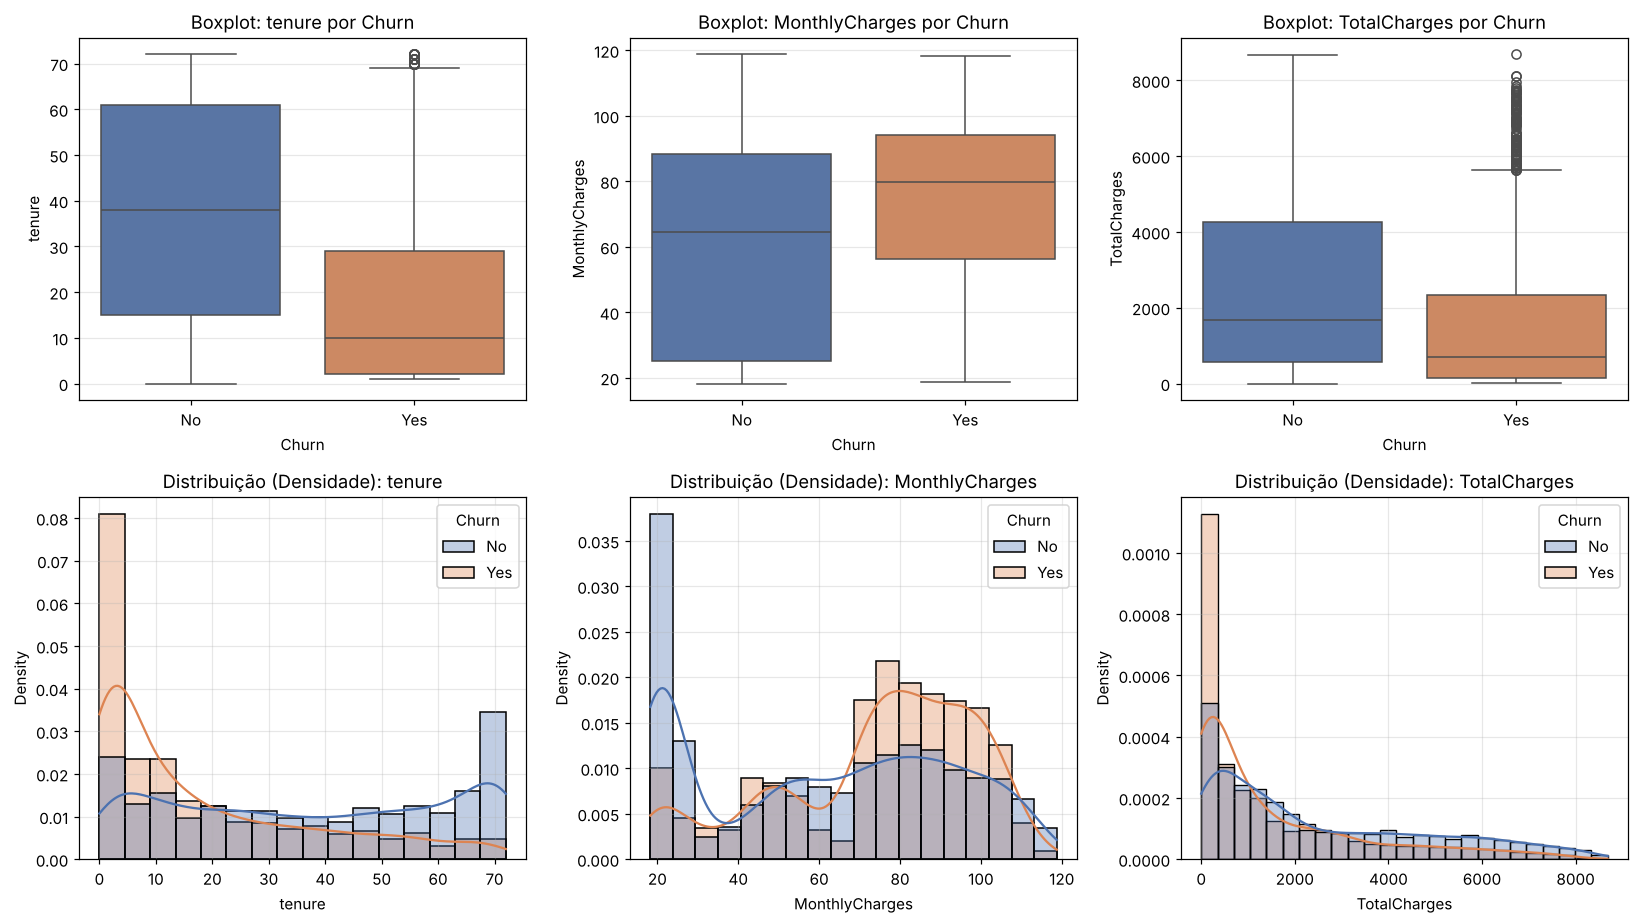

In [4]:
# 2.2 Estatísticas descritivas numéricas por classe
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
print("\nEstatísticas numéricas segmentadas por Churn:")
display(df.groupby("Churn")[num_cols].agg(["count", "mean", "median", "std", "min", "max"]).round(2))

fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
for col_idx, col in enumerate(num_cols):
    sns.boxplot(
        data=df, x="Churn", y=col, hue="Churn",
        palette={"No": "#4C72B0", "Yes": "#DD8452"}, legend=False, ax=axes[0, col_idx]
    )
    axes[0, col_idx].set_title(f"Boxplot: {col} por Churn")
    axes[0, col_idx].grid(axis="y", alpha=0.3)

    sns.histplot(
        data=df, x=col, hue="Churn", kde=True, stat="density", common_norm=False,
        palette={"No": "#4C72B0", "Yes": "#DD8452"}, alpha=0.35, ax=axes[1, col_idx]
    )
    axes[1, col_idx].set_title(f"Distribuição (Densidade): {col}")
    axes[1, col_idx].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Resumo de Churn (%) e tamanho amostral por categoria:

--- Contract ---


,n,churns,pct_base,taxa_churn_pct
Contract,,,,
Month-to-month,3875,1655,55.02,42.71
One year,1473,166,20.91,11.27
Two year,1695,48,24.07,2.83



--- InternetService ---


,n,churns,pct_base,taxa_churn_pct
InternetService,,,,
Fiber optic,3096,1297,43.96,41.89
DSL,2421,459,34.37,18.96
No,1526,113,21.67,7.40



--- PaymentMethod ---


,n,churns,pct_base,taxa_churn_pct
PaymentMethod,,,,
Electronic check,2365,1071,33.58,45.29
Mailed check,1612,308,22.89,19.11
Bank transfer (automatic),1544,258,21.92,16.71
Credit card (automatic),1522,232,21.61,15.24


... (22 outputs left out)


--- MultipleLines ---


,n,churns,pct_base,taxa_churn_pct
MultipleLines,,,,
Yes,2971,850,42.18,28.61
No,3390,849,48.13,25.04
No phone service,682,170,9.68,24.93



--- gender ---


,n,churns,pct_base,taxa_churn_pct
gender,,,,
Female,3488,939,49.52,26.92
Male,3555,930,50.48,26.16


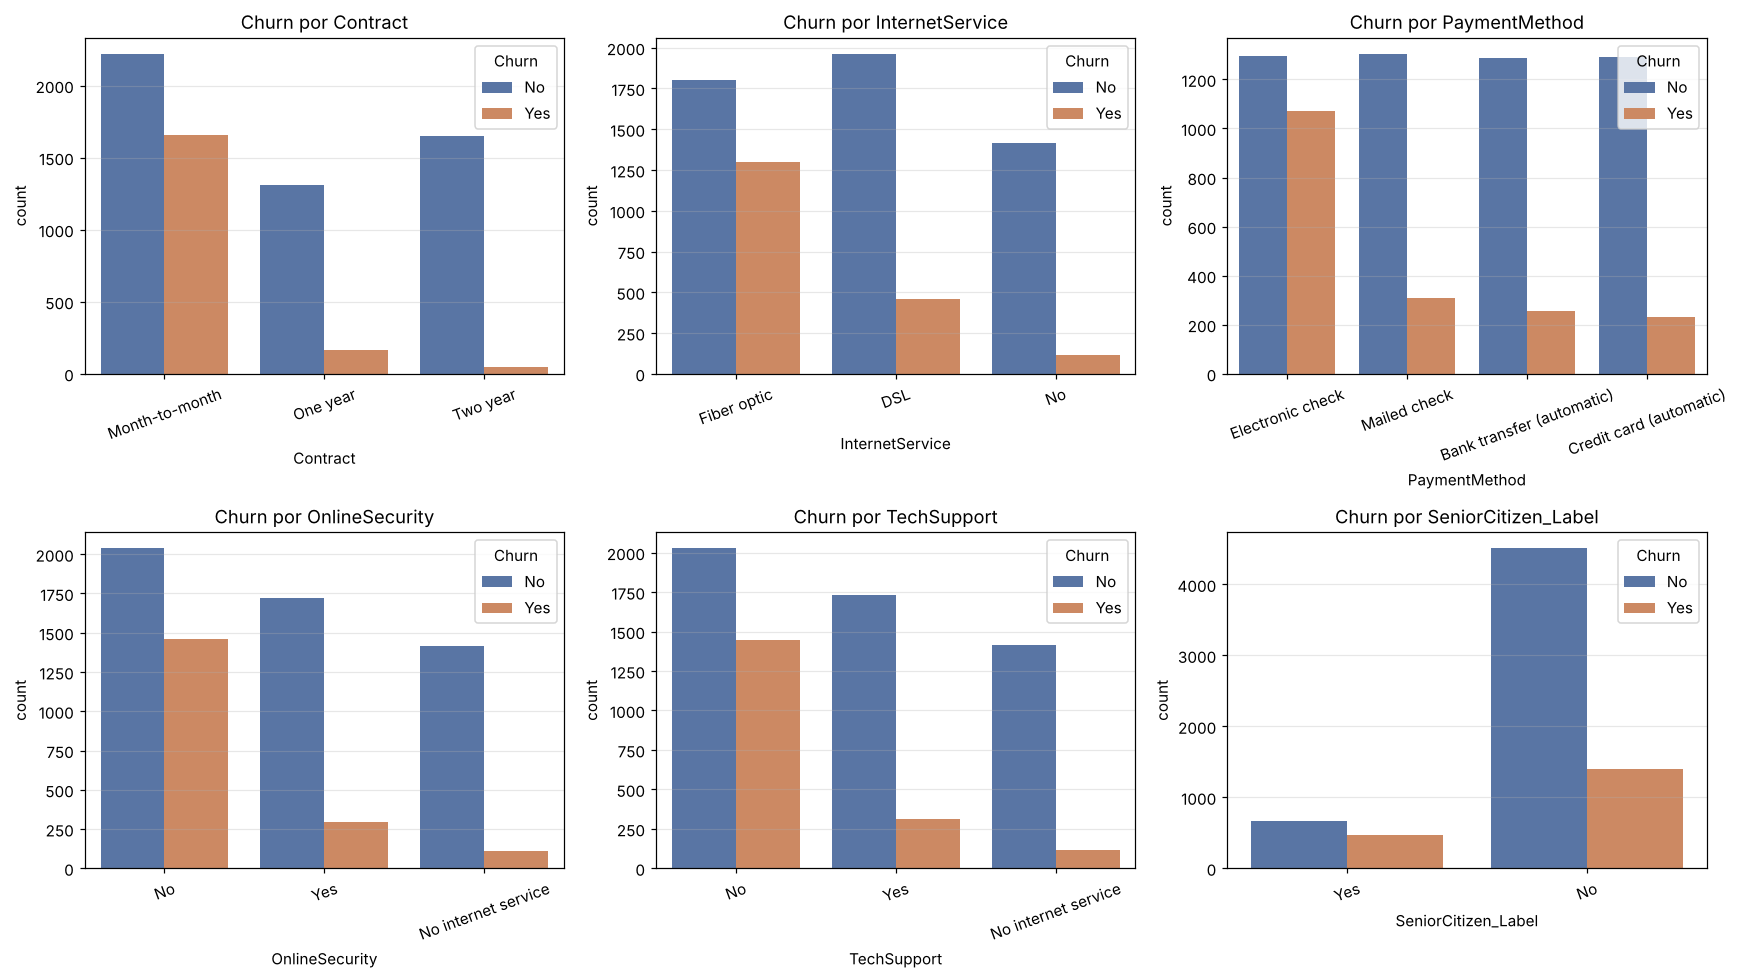

In [5]:
# 2.3 Taxa de Churn e tamanho dos grupos (n) em todas as variáveis categóricas
todas_categoricas = [
    "Contract", "InternetService", "PaymentMethod",
    "OnlineSecurity", "TechSupport", "OnlineBackup", "DeviceProtection",
    "StreamingTV", "StreamingMovies", "PaperlessBilling",
    "SeniorCitizen_Label", "Partner", "Dependents",
    "PhoneService", "MultipleLines", "gender",
]

print("Resumo de Churn (%) e tamanho amostral por categoria:")
for col in todas_categoricas:
    resumo_cat = (
        df.groupby(col)["Churn_Binario"]
        .agg(n="count", churns="sum", taxa="mean")
        .assign(
            pct_base=lambda d: (d["n"] / len(df) * 100).round(2),
            taxa_churn_pct=lambda d: (d["taxa"] * 100).round(2),
        )
        .drop(columns="taxa")
        .sort_values("taxa_churn_pct", ascending=False)
    )
    print(f"\n--- {col} ---")
    display(resumo_cat)

# Painel visual dos principais direcionadores categóricos
principais_cats = [
    "Contract", "InternetService", "PaymentMethod",
    "OnlineSecurity", "TechSupport", "SeniorCitizen_Label",
]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.ravel(), principais_cats):
    ordem = df.groupby(col)["Churn_Binario"].mean().sort_values(ascending=False).index
    sns.countplot(
        data=df, x=col, hue="Churn", order=ordem,
        palette={"No": "#4C72B0", "Yes": "#DD8452"}, ax=ax
    )
    ax.set_title(f"Churn por {col}")
    ax.tick_params(axis="x", rotation=20)
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


Correlação linear (Pearson) — Variáveis numéricas:


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn_Binario
SeniorCitizen,1.0000,0.0166,0.2202,0.1030,0.1509
tenure,0.0166,1.0000,0.2479,0.8262,-0.3522
MonthlyCharges,0.2202,0.2479,1.0000,0.6512,0.1934
TotalCharges,0.1030,0.8262,0.6512,1.0000,-0.1983
Churn_Binario,0.1509,-0.3522,0.1934,-0.1983,1.0000


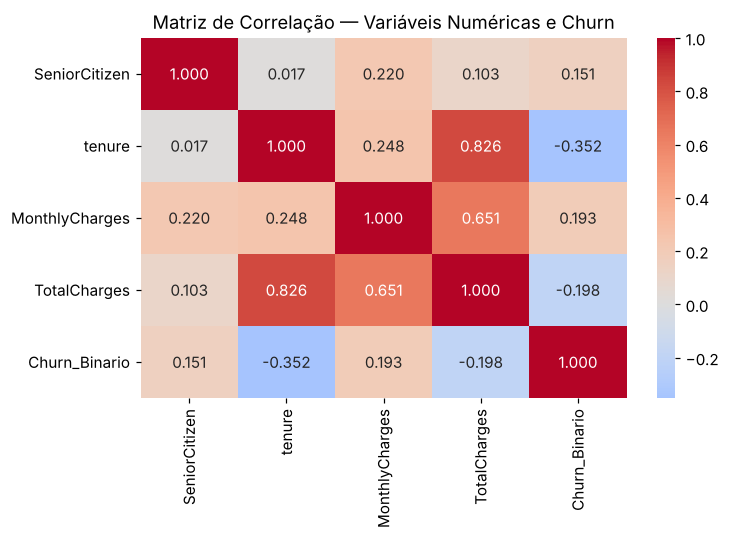

In [6]:
# 2.4 Matriz de correlação numérica
cols_corr = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges", "Churn_Binario"]
corr_mat = df[cols_corr].corr()
print("\nCorrelação linear (Pearson) — Variáveis numéricas:")
display(corr_mat.round(4))

plt.figure(figsize=(7, 5))
sns.heatmap(corr_mat, annot=True, fmt=".3f", cmap="coolwarm", center=0)
plt.title("Matriz de Correlação — Variáveis Numéricas e Churn")
plt.tight_layout()
plt.show()

In [7]:
# 2.5 Interação entre tempo de permanência, contrato e valor cobrado (com tamanho dos grupos)
# (usa uma cópia: as colunas auxiliares NÃO entram na matriz de preditores)
aux = df.assign(
    faixa_tenure=pd.cut(df["tenure"], bins=[-1, 6, 12, 24, 48, 72], labels=["0-6", "7-12", "13-24", "25-48", "49-72"]),
    faixa_mensalidade=pd.qcut(df["MonthlyCharges"], 4, labels=["Q1 (menor)", "Q2", "Q3", "Q4 (maior)"]),
)

tab_tc = aux.pivot_table(index="faixa_tenure", columns="Contract", values="Churn_Binario",
                         aggfunc=["count", "mean"], observed=True)
tab_tc["mean"] = (tab_tc["mean"] * 100).round(2)
print("Tempo de permanência (meses) x Contrato — n de clientes e taxa de churn (%):")
display(tab_tc)

tab_mc = aux.groupby("faixa_mensalidade", observed=True)["Churn_Binario"].agg(n="count", taxa_churn_pct=lambda s: round(s.mean() * 100, 2))
print("\nFaixas (quartis) de MonthlyCharges — n e taxa de churn (%):")
display(tab_mc)

tab_mc_ct = aux.pivot_table(index="faixa_mensalidade", columns="Contract", values="Churn_Binario",
                            aggfunc=["count", "mean"], observed=True)
tab_mc_ct["mean"] = (tab_mc_ct["mean"] * 100).round(2)
print("\nMonthlyCharges (quartis) x Contrato — n e taxa de churn (%):")
display(tab_mc_ct)

Tempo de permanência (meses) x Contrato — n de clientes e taxa de churn (%):


count                             mean                  
Contract     Month-to-month One year Two year Month-to-month One year Two year
faixa_tenure                                                                  
0-6                    1413       39       29          55.20    10.26     0.00
7-12                    581       85       39          42.00    10.59     0.00
13-24                   737      197       90          37.72     8.12     0.00
25-48                   802      518      274          32.92    10.62     2.19
49-72                   342      634     1263          26.02    12.93     3.33


Faixas (quartis) de MonthlyCharges — n e taxa de churn (%):


,n,taxa_churn_pct
faixa_mensalidade,,
Q1 (menor),1762,11.24
Q2,1766,24.58
Q3,1757,37.51
Q4 (maior),1758,32.88



MonthlyCharges (quartis) x Contrato — n e taxa de churn (%):


count                             mean           \
Contract          Month-to-month One year Two year Month-to-month One year   
faixa_mensalidade                                                            
Q1 (menor)                   723      394      645          25.03     3.05   
Q2                          1109      371      286          35.62     8.63   
Q3                          1173      262      322          53.28    11.07   
Q4 (maior)                   870      446      442          52.18    20.85   

                            
Contract          Two year  
faixa_mensalidade           
Q1 (menor)            0.78  
Q2                    2.45  
Q3                    1.55  
Q4 (maior)            7.01

### Leitura da análise exploratória

*Todos os valores citados vêm das saídas executadas acima (e nas seções seguintes), com `RANDOM_STATE = 42`.*

- **Alvo desbalanceado:** 26,54% de cancelamentos (1.869 de 7.043). Por isso, a acurácia isolada é pouco informativa.
- **Tempo de permanência:** quem cancela tem mediana de 10 meses (média 17,98) contra 38 meses (média 37,57) dos retidos; a correlação de `tenure` com o churn é -0,3522.
- **Valores cobrados:** a mediana de `MonthlyCharges` é maior entre quem cancela (79,65 contra 64,43; correlação +0,1934). `TotalCharges` é menor entre quem cancela (mediana 703,55 contra 1.679,52), mas isso reflete sobretudo o menor tempo de casa: `TotalCharges ≈ tenure × MonthlyCharges` (correlação de 0,8262 com `tenure`; correlação com o churn de -0,1983).
- **Contrato:** mensal 42,71% de churn (n = 3.875), anual 11,27% (n = 1.473), bienal 2,83% (n = 1.695).
- **Internet:** fibra óptica 41,89% (n = 3.096), DSL 18,96% (n = 2.421), sem internet 7,40% (n = 1.526).
- **Pagamento:** cheque eletrônico 45,29% (n = 2.365), contra 15,24% a 19,11% nas demais formas (n entre 1.522 e 1.612).
- **Serviços:** sem `OnlineSecurity` 41,77% (n = 3.498) contra 14,61% com o serviço (n = 2.019); sem `TechSupport` 41,64% contra 15,17%.
- **Perfil:** idosos 41,68% (n = 1.142) contra 23,61%; sem parceiro 32,96% contra 19,66%; sem dependentes 31,28% contra 15,45%; fatura sem papel (`PaperlessBilling`) 33,57% contra 16,33%.
- **Pouca ou nenhuma associação:** `gender` (26,92% contra 26,16%), `PhoneService` (26,71% contra 24,93%) e os serviços de streaming (cerca de 30% a 34%).

**Tamanho dos grupos:** os grupos das variáveis categóricas têm de centenas a milhares de clientes (o menor, "sem serviço telefônico", tem 682), então as taxas acima são estáveis. Já as células com poucos clientes da tabela cruzada abaixo (por exemplo, contrato bienal com até 6 meses: n = 29) devem ser lidas com cautela.

**Interação tempo × contrato × mensalidade (tabelas 2.5):**

- No contrato mensal, o churn cai com o tempo de casa, de **55,20%** (0 a 6 meses, n = 1.413) para 26,02% (49 a 72 meses, n = 342). Além disso, 95,4% dos clientes com até 6 meses (1.413 de 1.481) estão no contrato mensal: o segmento "novo + sem fidelidade" é o de maior risco.
- No contrato anual o churn fica em torno de 8% a 13% em todas as faixas de tempo, e no bienal é 0% até 24 meses e 2,19% a 3,33% depois.
- Por quartil de `MonthlyCharges`, o churn é 11,24%, 24,58%, 37,51% e 32,88%. A leve queda do terceiro para o quarto quartil coincide com a composição: 50,5% do quarto quartil está em contratos longos, contra 33,2% do terceiro.
- **Dentro de cada tipo de contrato** a mensalidade mais alta se associa a mais churn (mensal: 25,03% no 1º quartil contra 52,18% no 4º; anual: 3,05% contra 20,85%; bienal: 0,78% contra 7,01%), mas o tipo de contrato pesa mais do que a mensalidade: um cliente do contrato mensal de menor mensalidade (25,03%) cancela mais do que um do contrato bienal de maior mensalidade (7,01%).

Essas são associações **marginais** (uma variável por vez); tempo, contrato, internet e forma de pagamento se sobrepõem, o que os modelos das próximas seções tratam de forma conjunta.

## 3. Divisão Estratificada, Investigação de Redundâncias e Engenharia de Atributos

Para cumprir rigorosamente os cuidados metodológicos contra **vazamento de dados**:
1. Realizamos o `train_test_split` estratificado (**80% treino / 20% teste**) **antes** de calcular escalas (`StandardScaler`), codificadores (`OneHotEncoder`), estatísticas de colinearidade (VIF) ou validações de seleção de variáveis;
2. Investigamos duas redundâncias estruturais relevantes no conjunto de treino:
   - **Redundância perfeita pós-*One-Hot Encoding*:** o nível `"No phone service"` em `MultipleLines` é exatamente idêntico a `PhoneService == "No"`, e o nível `"No internet service"` repete-se identicamente em **6 colunas** (`OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`), duplicando `InternetService == "No"`.
   - **Multicolinearidade numérica:** `TotalCharges` é aproximadamente o produto `tenure × MonthlyCharges`, gerando alto VIF e instabilidade de sinais em coeficientes lineares quando todas atuam em conjunto; além disso, avaliamos se `gender` agrega poder preditivo relevante em validação cruzada (conforme observado na tabela da Seção 2.3).
3. Executamos um experimento em **Validação Cruzada Estratificada (5 folds)** apenas no treino comparando:
   - `1_Base_Completa`: todas as 19 preditoras válidas com `OneHotEncoder(drop="first")` + `StandardScaler`;
   - `2_Sem_Redundancias`: colapso dos níveis redundantes (`"No internet service"` e `"No phone service"` mapeados para `"No"`) + remoção de `gender` e `TotalCharges`;
   - `3_Engenharia_Features`: criação de `ServicesCount` (quantidade de serviços contratados), `AvgMonthlySpend` (`TotalCharges / max(tenure, 1)`), `ChargePerService` e `IsNewCustomer` (`tenure <= 6`), mantendo remoção das colunas redundantes.

In [8]:
# Remoção exclusiva de identificador e colunas auxiliares de texto
X_full = df.drop(columns=["customerID", "Churn", "Churn_Binario", "SeniorCitizen_Label"])
y = df["Churn_Binario"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X_full, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print(f"Treino: {X_train.shape} | Taxa de Churn = {y_train.mean()*100:.2f}%")
print(f"Teste:  {X_test.shape} | Taxa de Churn = {y_test.mean()*100:.2f}%")

# Diagnóstico de colinearidade (VIF) exclusivamente no TREINO
def calcular_vif(df_num: pd.DataFrame) -> pd.DataFrame:
    vifs = []
    for c in df_num.columns:
        X_outros = df_num.drop(columns=[c])
        r2 = LinearRegression().fit(X_outros, df_num[c]).score(X_outros, df_num[c])
        vif = np.inf if r2 >= 0.999999 else 1.0 / (1.0 - r2)
        vifs.append({"variavel": c, "R2_contra_outras": round(r2, 4), "VIF": round(vif, 2)})
    return pd.DataFrame(vifs)

print("\nDiagnóstico VIF (Multicolinearidade Numérica no Treino):")
display(calcular_vif(X_train[["tenure", "MonthlyCharges", "TotalCharges"]]))

cols_internet_addons = [
    "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies",
]

redund_internet = all(
    ((X_train[c] == "No internet service") == (X_train["InternetService"] == "No")).all()
    for c in cols_internet_addons
)
redund_fone = (
    (X_train["MultipleLines"] == "No phone service") == (X_train["PhoneService"] == "No")
).all()
print(f"6 colunas 'No internet service' são 100% idênticas a InternetService=='No'? {redund_internet}")
print(f"Coluna 'No phone service' é 100% idêntica a PhoneService=='No'?            {redund_fone}")


def preparar_representacao(df_in: pd.DataFrame, modo: str) -> pd.DataFrame:
    '''Transformação determinística linha a linha (sem uso de estatísticas globais).'''
    out = df_in.copy()
    if modo == "1_Base_Completa":
        return out

    for c in cols_internet_addons:
        out[c] = out[c].replace({"No internet service": "No"})
    out["MultipleLines"] = out["MultipleLines"].replace({"No phone service": "No"})

    if modo == "2_Sem_Redundancias":
        return out.drop(columns=["gender", "TotalCharges"])

    if modo == "3_Engenharia_Features":
        servicos = cols_internet_addons + ["PhoneService", "MultipleLines"]
        out["ServicesCount"] = sum((out[c] == "Yes").astype(int) for c in servicos)
        out["AvgMonthlySpend"] = out["TotalCharges"] / np.maximum(out["tenure"], 1)
        out["ChargePerService"] = out["MonthlyCharges"] / (out["ServicesCount"] + 1)
        out["IsNewCustomer"] = (out["tenure"] <= 6).astype(int)
        return out.drop(columns=["gender", "TotalCharges"])

    raise ValueError(f"Modo desconhecido: {modo}")


def criar_preprocessador(df_exemplo: pd.DataFrame) -> ColumnTransformer:
    num_c = df_exemplo.select_dtypes(include=["int64", "float64", "int32", "float32"]).columns.tolist()
    cat_c = [c for c in df_exemplo.columns if c not in num_c]
    return ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), num_c),
            ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), cat_c),
        ],
        verbose_feature_names_out=False,
    )


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
ablation_rows = []

for modo in ["1_Base_Completa", "2_Sem_Redundancias", "3_Engenharia_Features"]:
    X_var = preparar_representacao(X_train, modo)
    prep_var = criar_preprocessador(X_var)
    n_pos_ohe = clone(prep_var).fit(X_var).transform(X_var.iloc[:1]).shape[1]

    for nome_clf, clf in [
        ("LogisticRegression", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
        ("XGBoost", XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=1)),
    ]:
        pipe_var = ImbPipeline([("prep", clone(prep_var)), ("clf", clf)])
        cv_out = cross_validate(
            pipe_var, X_var, y_train, cv=cv,
            scoring={"roc_auc": "roc_auc", "ap": "average_precision"}, n_jobs=-1
        )
        ablation_rows.append({
            "Representacao": modo,
            "Modelo": nome_clf,
            "Dimensao_Pos_OHE": int(n_pos_ohe),
            "CV_ROC_AUC_Mean": cv_out["test_roc_auc"].mean(),
            "CV_ROC_AUC_Std": cv_out["test_roc_auc"].std(),
            "CV_AP_Mean": cv_out["test_ap"].mean(),
            "CV_AP_Std": cv_out["test_ap"].std(),
        })

ablation_df = pd.DataFrame(ablation_rows).sort_values(["Modelo", "CV_AP_Mean"], ascending=[True, False])
print("\nResultado em CV (5 folds) — Impacto de Remoção de Redundâncias e Engenharia:")
display(ablation_df.round(4))

# Seleção estritamente guiada pela média CV Average Precision no conjunto de treino (zero leakage)
resumo_modos = ablation_df.groupby("Representacao")["CV_AP_Mean"].mean().sort_values(ascending=False)
MODO_ESCOLHIDO = resumo_modos.index[0]
print(f"\nRepresentação com maior Average Precision médio em CV: {MODO_ESCOLHIDO}")

Treino: (5634, 19) | Taxa de Churn = 26.54%
Teste:  (1409, 19) | Taxa de Churn = 26.54%

Diagnóstico VIF (Multicolinearidade Numérica no Treino):


,variavel,R2_contra_outras,VIF
0,tenure,0.8314,5.93
1,MonthlyCharges,0.6904,3.23
2,TotalCharges,0.8967,9.68


6 colunas 'No internet service' são 100% idênticas a InternetService=='No'? True
Coluna 'No phone service' é 100% idêntica a PhoneService=='No'?            True



Resultado em CV (5 folds) — Impacto de Remoção de Redundâncias e Engenharia:


,Representacao,Modelo,Dimensao_Pos_OHE,CV_ROC_AUC_Mean,CV_ROC_AUC_Std,CV_AP_Mean,CV_AP_Std
4,3_Engenharia_Features,LogisticRegression,25,0.8477,0.0113,0.6615,0.0153
0,1_Base_Completa,LogisticRegression,30,0.8462,0.0126,0.6615,0.0192
2,2_Sem_Redundancias,LogisticRegression,21,0.8451,0.0121,0.6601,0.0181
1,1_Base_Completa,XGBoost,30,0.8258,0.0077,0.6248,0.0141
3,2_Sem_Redundancias,XGBoost,21,0.8207,0.0074,0.6212,0.0209
5,3_Engenharia_Features,XGBoost,25,0.8201,0.0112,0.6170,0.0127



Representação com maior Average Precision médio em CV: 1_Base_Completa


### Conclusão da seleção e transformação de variáveis

- **Codificação:** as variáveis categóricas usam `OneHotEncoder(drop="first", handle_unknown="ignore")` (a categoria de referência de `Contract` é `Month-to-month`, por isso aparecem apenas `Contract_One year` e `Contract_Two year`). `customerID` é excluído por ser um identificador único (7.043 valores distintos), sem informação generalizável.
- **Padronização:** `StandardScaler` nas numéricas. É necessária para a Regressão Logística (regularização L2 e coeficientes comparáveis) e inócua para as árvores. Codificador e padronizador são ajustados **somente nos dados de treino de cada rodada**, dentro do `Pipeline`.
- **Redundâncias confirmadas:** as 6 colunas "No internet service" são idênticas a `InternetService == "No"`, e "No phone service" é idêntica a `PhoneService == "No"`. Entre as numéricas, `TotalCharges` tem VIF de 9,68 (`tenure` 5,93; `MonthlyCharges` 3,23).
- **Resultado da ablação (validação cruzada, apenas no treino):** a representação **completa (30 colunas)** teve a melhor média de Average Precision (Regressão Logística 0,6615; XGBoost 0,6248). Remover as redundâncias baixou o AP da Regressão Logística para 0,6601 e o do XGBoost para 0,6212; a engenharia de atributos empatou em AP na Regressão Logística (0,6615, com AUC levemente maior, 0,8477 contra 0,8462) e piorou no XGBoost (0,6170). Todas essas diferenças são **menores que o desvio-padrão entre folds** (0,013 a 0,021), isto é, **não há evidência de que remover colunas ou criar variáveis melhore o resultado**. A explicação mais provável é que a regularização da Regressão Logística absorve a colinearidade e as árvores não são afetadas por ela. Mantivemos, portanto, a base completa.
- **Implicação para a interpretação:** a colinearidade entre `tenure`, `MonthlyCharges` e `TotalCharges` pouco afeta a previsão, mas torna os **coeficientes individuais** da Regressão Logística instáveis (ver Seção 7).

## 4 & 5. Modelagem Supervisionada, Hiperparâmetros e Estratégias de Balanceamento

Comparamos **3 famílias de classificadores** (`LogisticRegression`, `RandomForest` e `XGBoost`) sob **4 cenários de desbalanceamento** usando exatamente o mesmo protocolo experimental:
1. **`1_Original`** — distribuição natural de treino (~73,5% vs. ~26,5%);
2. **`2_Class_Weight`** — penalização proporcional inversa à frequência das classes (`class_weight="balanced"` / `scale_pos_weight`);
3. **`3_SMOTE`** — *oversampling* sintético da classe minoritária aplicado **apenas** nos folds de treino via `imblearn.pipeline.Pipeline`;
4. **`4_Undersampling`** — subamostragem aleatória da classe majoritária (`RandomUnderSampler`) aplicada **apenas** nos folds de treino.

Todos os hiperparâmetros são selecionados via `GridSearchCV` com `StratifiedKFold(n_splits=5)` maximizando **`average_precision`** (área sob a curva Precision-Recall), critério mais informativo que a acurácia sob desbalanceamento. O conjunto de teste permanece intocado até a avaliação final.

In [9]:
X_tr_mod = preparar_representacao(X_train, MODO_ESCOLHIDO)
X_te_mod = preparar_representacao(X_test, MODO_ESCOLHIDO)
preprocessador = criar_preprocessador(X_tr_mod)

# Razão de desbalanceamento calculada exclusivamente no conjunto de treino
scale_pos = float((y_train == 0).sum() / (y_train == 1).sum())
print(f"Fator scale_pos_weight (y_train): {scale_pos:.4f} | Representação ativa: {MODO_ESCOLHIDO}")

estrategias = {
    "1_Original": None,
    "2_Class_Weight": "class_weight",
    "3_SMOTE": SMOTE(random_state=RANDOM_STATE),
    "4_Undersampling": RandomUnderSampler(random_state=RANDOM_STATE),
}

modelos_grids = {
    "LogisticRegression": (
        LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
        {"clf__C": [0.01, 0.1, 1.0, 10.0]},
    ),
    "RandomForest": (
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
        {"clf__n_estimators": [200, 300], "clf__max_depth": [6, 10, 14]},
    ),
    "XGBoost": (
        XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=1),
        {"clf__n_estimators": [150, 250], "clf__max_depth": [3, 5], "clf__learning_rate": [0.05, 0.1]},
    ),
}

resultados = []
melhores_pipelines = {}

for est_nome, est_obj in estrategias.items():
    for mod_nome, (mod_base, grid) in modelos_grids.items():
        clf = clone(mod_base)
        sampler_step = "passthrough"

        if est_obj == "class_weight":
            if mod_nome == "XGBoost":
                clf.set_params(scale_pos_weight=scale_pos)
            else:
                clf.set_params(class_weight="balanced")
        elif est_obj is not None:
            sampler_step = clone(est_obj)

        pipe = ImbPipeline([
            ("prep", clone(preprocessador)),
            ("sampler", sampler_step),
            ("clf", clf),
        ])

        gs = GridSearchCV(
            estimator=pipe,
            param_grid=grid,
            cv=cv,
            scoring="average_precision",
            n_jobs=-1,
        )
        gs.fit(X_tr_mod, y_train)

        best_pipe = gs.best_estimator_
        melhores_pipelines[(est_nome, mod_nome)] = best_pipe

        y_pred = best_pipe.predict(X_te_mod)
        y_prob = best_pipe.predict_proba(X_te_mod)[:, 1]

        resultados.append({
            "Estrategia": est_nome,
            "Modelo": mod_nome,
            "Melhores_Params": gs.best_params_,
            "CV_AP": gs.best_score_,
            "Test_Precision": precision_score(y_test, y_pred, zero_division=0),
            "Test_Recall": recall_score(y_test, y_pred),
            "Test_F1": f1_score(y_test, y_pred),
            "Test_ROC_AUC": roc_auc_score(y_test, y_prob),
            "Test_AP": average_precision_score(y_test, y_prob),
        })

df_resultados = (
    pd.DataFrame(resultados)
    .sort_values(["Test_AP", "Test_ROC_AUC"], ascending=False)
    .reset_index(drop=True)
)
print("\nTabela Comparativa Geral no Conjunto de Teste (ordenada por Test_AP):")
display(df_resultados.drop(columns=["Melhores_Params"]).round(4))

print("\nMelhores Hiperparâmetros (selecionados exclusivamente em CV):")
for _, row in df_resultados.iterrows():
    print(f" - {row['Estrategia']:16s} | {row['Modelo']:18s} -> {row['Melhores_Params']}")

Fator scale_pos_weight (y_train): 2.7686 | Representação ativa: 1_Base_Completa



Tabela Comparativa Geral no Conjunto de Teste (ordenada por Test_AP):


,Estrategia,Modelo,CV_AP,Test_Precision,Test_Recall,Test_F1,Test_ROC_AUC,Test_AP
0,1_Original,XGBoost,0.6674,0.6610,0.5160,0.5796,0.8459,0.6638
1,4_Undersampling,XGBoost,0.6607,0.5068,0.7995,0.6203,0.8448,0.6602
2,2_Class_Weight,XGBoost,0.6663,0.5077,0.7941,0.6194,0.8407,0.6597
3,4_Undersampling,RandomForest,0.6577,0.5050,0.8048,0.6206,0.8432,0.6551
4,1_Original,RandomForest,0.6615,0.6667,0.4385,0.5290,0.8434,0.6546
5,3_SMOTE,XGBoost,0.6608,0.5663,0.6738,0.6154,0.8426,0.6531
6,2_Class_Weight,RandomForest,0.6574,0.5083,0.8182,0.6270,0.8423,0.6489
7,3_SMOTE,RandomForest,0.6509,0.5466,0.7059,0.6161,0.8422,0.6441
8,1_Original,LogisticRegression,0.6615,0.6604,0.5615,0.6069,0.8422,0.6350
9,4_Undersampling,LogisticRegression,0.6615,0.5113,0.7861,0.6196,0.8430,0.6347



Melhores Hiperparâmetros (selecionados exclusivamente em CV):
 - 1_Original       | XGBoost            -> {'clf__learning_rate': 0.05, 'clf__max_depth': 3, 'clf__n_estimators': 150}
 - 4_Undersampling  | XGBoost            -> {'clf__learning_rate': 0.05, 'clf__max_depth': 3, 'clf__n_estimators': 150}
 - 2_Class_Weight   | XGBoost            -> {'clf__learning_rate': 0.1, 'clf__max_depth': 3, 'clf__n_estimators': 150}
 - 4_Undersampling  | RandomForest       -> {'clf__max_depth': 6, 'clf__n_estimators': 300}
 - 1_Original       | RandomForest       -> {'clf__max_depth': 6, 'clf__n_estimators': 300}
 - 3_SMOTE          | XGBoost            -> {'clf__learning_rate': 0.05, 'clf__max_depth': 3, 'clf__n_estimators': 250}
 - 2_Class_Weight   | RandomForest       -> {'clf__max_depth': 6, 'clf__n_estimators': 300}
 - 3_SMOTE          | RandomForest       -> {'clf__max_depth': 10, 'clf__n_estimators': 200}
 - 1_Original       | LogisticRegression -> {'clf__C': 1.0}
 - 4_Undersampling  | Logisti

In [10]:
# 4/5.b Efeito de cada estratégia relativo à distribuição original (mesmo algoritmo, mesmo protocolo)
base = df_resultados[df_resultados["Estrategia"] == "1_Original"].set_index("Modelo")
metricas = ["Test_Precision", "Test_Recall", "Test_F1", "Test_ROC_AUC", "Test_AP"]
linhas = []
for _, r in df_resultados[df_resultados["Estrategia"] != "1_Original"].iterrows():
    d = {"Modelo": r["Modelo"], "Estrategia": r["Estrategia"]}
    for m in metricas:
        d["Δ " + m.replace("Test_", "")] = r[m] - base.loc[r["Modelo"], m]
    linhas.append(d)
df_delta = pd.DataFrame(linhas).sort_values(["Modelo", "Estrategia"]).reset_index(drop=True)
print("Diferença em relação ao treinamento com a distribuição original (positivo = melhora):")
display(df_delta.round(4))

Diferença em relação ao treinamento com a distribuição original (positivo = melhora):


,Modelo,Estrategia,Δ Precision,Δ Recall,Δ F1,Δ ROC_AUC,Δ AP
0,LogisticRegression,2_Class_Weight,-0.1508,0.2219,0.0106,-0.0008,-0.0005
1,LogisticRegression,3_SMOTE,-0.1518,0.2299,0.0123,-0.0018,-0.0053
2,LogisticRegression,4_Undersampling,-0.1491,0.2246,0.0127,0.0009,-0.0003
3,RandomForest,2_Class_Weight,-0.1584,0.3797,0.0980,-0.0011,-0.0058
4,RandomForest,3_SMOTE,-0.1201,0.2674,0.0871,-0.0012,-0.0106
5,RandomForest,4_Undersampling,-0.1616,0.3663,0.0916,-0.0002,0.0005
6,XGBoost,2_Class_Weight,-0.1533,0.2781,0.0398,-0.0052,-0.0041
7,XGBoost,3_SMOTE,-0.0947,0.1578,0.0358,-0.0033,-0.0107
8,XGBoost,4_Undersampling,-0.1542,0.2834,0.0408,-0.0011,-0.0036


### Leitura da comparação entre classificadores e estratégias (conjunto de teste, limiar 0,50)

**Ranking (AP e ROC-AUC).** O melhor resultado é o do **XGBoost sem reamostragem** (AP = 0,6638; AUC = 0,8459), que também teve o maior AP em validação cruzada (0,6674). A vantagem é **pequena**: os melhores AP em CV de cada algoritmo são 0,6674 (XGBoost), 0,6615 (Regressão Logística) e 0,6615 (Random Forest), uma diferença de cerca de 0,006, menor que a variação entre folds (aproximadamente 0,015). No teste, a Regressão Logística fica 0,029 abaixo do XGBoost em AP e o Random Forest 0,009; as 12 combinações têm ROC-AUC entre 0,840 e 0,846. Com um único conjunto de teste (374 cancelamentos), isso não permite afirmar superioridade clara de um algoritmo.

**A conclusão depende da métrica:** AP e AUC favorecem o XGBoost sem reamostragem; precisão no limiar 0,50 é maior nos modelos sem reamostragem (Random Forest 0,6667, XGBoost 0,6610, Regressão Logística 0,6604); sensibilidade (0,8182) e F1 (0,6270) são maiores no Random Forest com ponderação de classes.

**Efeito do balanceamento (tabela de diferenças):**

- **Sensibilidade e F1 no limiar 0,50 melhoram:** a sensibilidade aumenta de 0,16 a 0,38 e o F1 de 0,01 (Regressão Logística) a 0,10 (Random Forest), **ao custo de precisão**, que cai de 0,09 a 0,16. Exemplo no XGBoost: sem reamostragem, 193 cancelamentos detectados, 181 perdidos e 99 falsos alarmes; com ponderação, 297 detectados, 77 perdidos e 288 falsos alarmes; com subamostragem, 299 / 75 / 291; com SMOTE, 252 / 122 / 193.
- **Ranking não melhora:** a variação do AP vai de -0,011 a +0,0005 e a do ROC-AUC de -0,005 a +0,001. O SMOTE reduziu o AP nos três algoritmos (-0,005 a -0,011).

Em outras palavras, ponderação e reamostragem principalmente **deslocam o ponto de operação** do classificador, sem melhorar a capacidade de separar as classes.

## 6. Avaliação no Teste, Matrizes de Confusão, Curvas ROC/PR, Limiar e Top 10%

Nesta seção avaliamos todos os resultados no conjunto de teste com distribuição original:
- **Matrizes de Confusão:** visualização explícita de Verdadeiros Positivos (churns capturados), Falsos Negativos (churns perdidos) e Falsos Positivos (custos de abordagem promocional) sob cada estratégia no algoritmo campeão;
- **Curvas ROC e Precision-Recall (PR):** comparação direta entre as 3 famílias de algoritmos **e** entre as 4 estratégias de balanceamento sobre o modelo vencedor, destacando o *baseline* aleatório na curva PR (`AP ≈ 0,2654`);
- **Sensibilidade ao Limiar de Decisão:** efeito de variar o ponto de corte de `0,15` a `0,70` nas probabilidades do modelo campeão sem reamostragem (`1_Original`, que preserva a calibração natural de risco);
- **Limiar escolhido sem olhar o teste:** além da grade de limiares (6.3), o limiar que maximiza o F1 é escolhido por validação cruzada no treino (6.3b) e só então avaliado no teste;
- **Simulação Estratégica Top 10%:** quantos cancelamentos reais a empresa consegue capturar ao concentrar a campanha de retenção apenas nos 10% de clientes com maior risco predito.

In [11]:
best_row_ap = df_resultados.iloc[0]
best_est_ap = best_row_ap["Estrategia"]
best_mod_ap = best_row_ap["Modelo"]
best_pipe_ap = melhores_pipelines[(best_est_ap, best_mod_ap)]

best_row_f1 = df_resultados.sort_values("Test_F1", ascending=False).iloc[0]
best_est_f1 = best_row_f1["Estrategia"]
best_mod_f1 = best_row_f1["Modelo"]

print(f"Campeão em ordenação probabilística (Test_AP): {best_mod_ap} | {best_est_ap} (AP={best_row_ap['Test_AP']:.4f}, AUC={best_row_ap['Test_ROC_AUC']:.4f})")
print(f"Campeão em equilíbrio F1 (limiar 0.50):        {best_mod_f1} | {best_est_f1} (F1={best_row_f1['Test_F1']:.4f}, Recall={best_row_f1['Test_Recall']:.4f})")

Campeão em ordenação probabilística (Test_AP): XGBoost | 1_Original (AP=0.6638, AUC=0.8459)
Campeão em equilíbrio F1 (limiar 0.50):        RandomForest | 2_Class_Weight (F1=0.6270, Recall=0.8182)


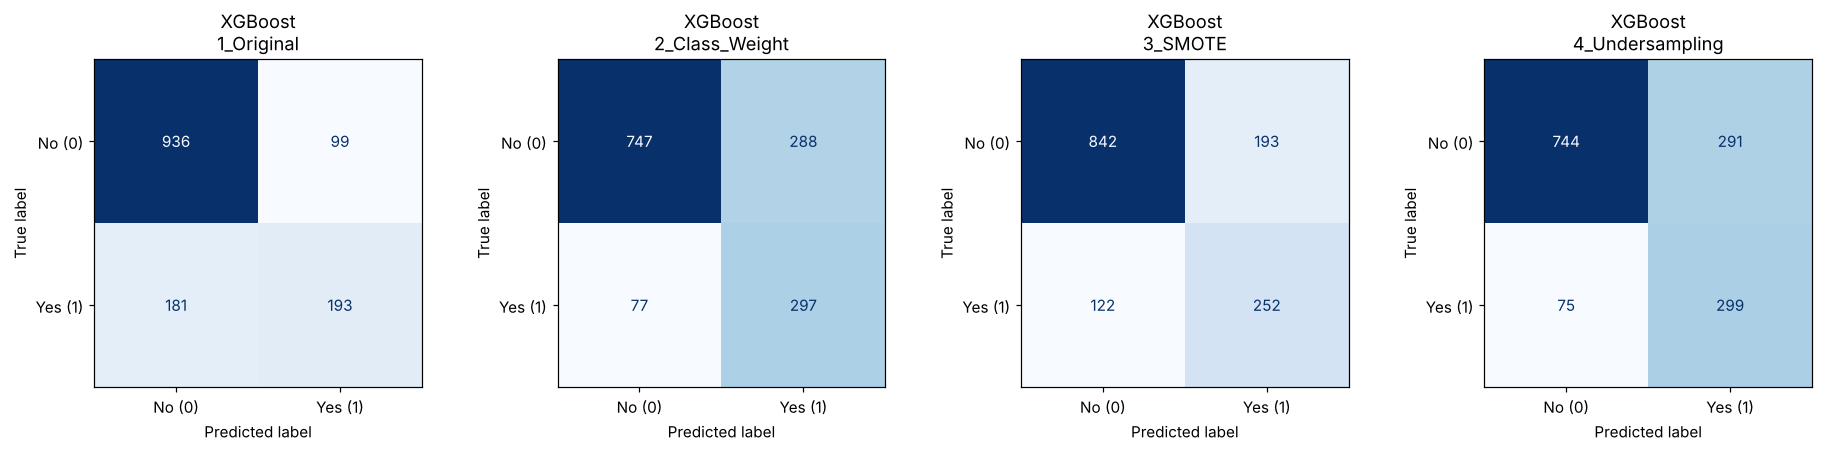


Relatório de Classificação Detalhado — RandomForest (2_Class_Weight):
              precision    recall  f1-score   support

No Churn (0)       0.92      0.71      0.80      1035
   Churn (1)       0.51      0.82      0.63       374

    accuracy                           0.74      1409
   macro avg       0.71      0.77      0.71      1409
weighted avg       0.81      0.74      0.76      1409



In [12]:
# 6.1 Matrizes de Confusão das 4 estratégias no algoritmo vencedor em AP
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, est_nome in zip(axes, estrategias.keys()):
    pipe_e = melhores_pipelines[(est_nome, best_mod_ap)]
    cm = confusion_matrix(y_test, pipe_e.predict(X_te_mod))
    ConfusionMatrixDisplay(cm, display_labels=["No (0)", "Yes (1)"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{best_mod_ap}\n{est_nome}")
plt.tight_layout()
plt.show()

print(f"\nRelatório de Classificação Detalhado — {best_mod_f1} ({best_est_f1}):")
print(classification_report(
    y_test,
    melhores_pipelines[(best_est_f1, best_mod_f1)].predict(X_te_mod),
    target_names=["No Churn (0)", "Churn (1)"],
))

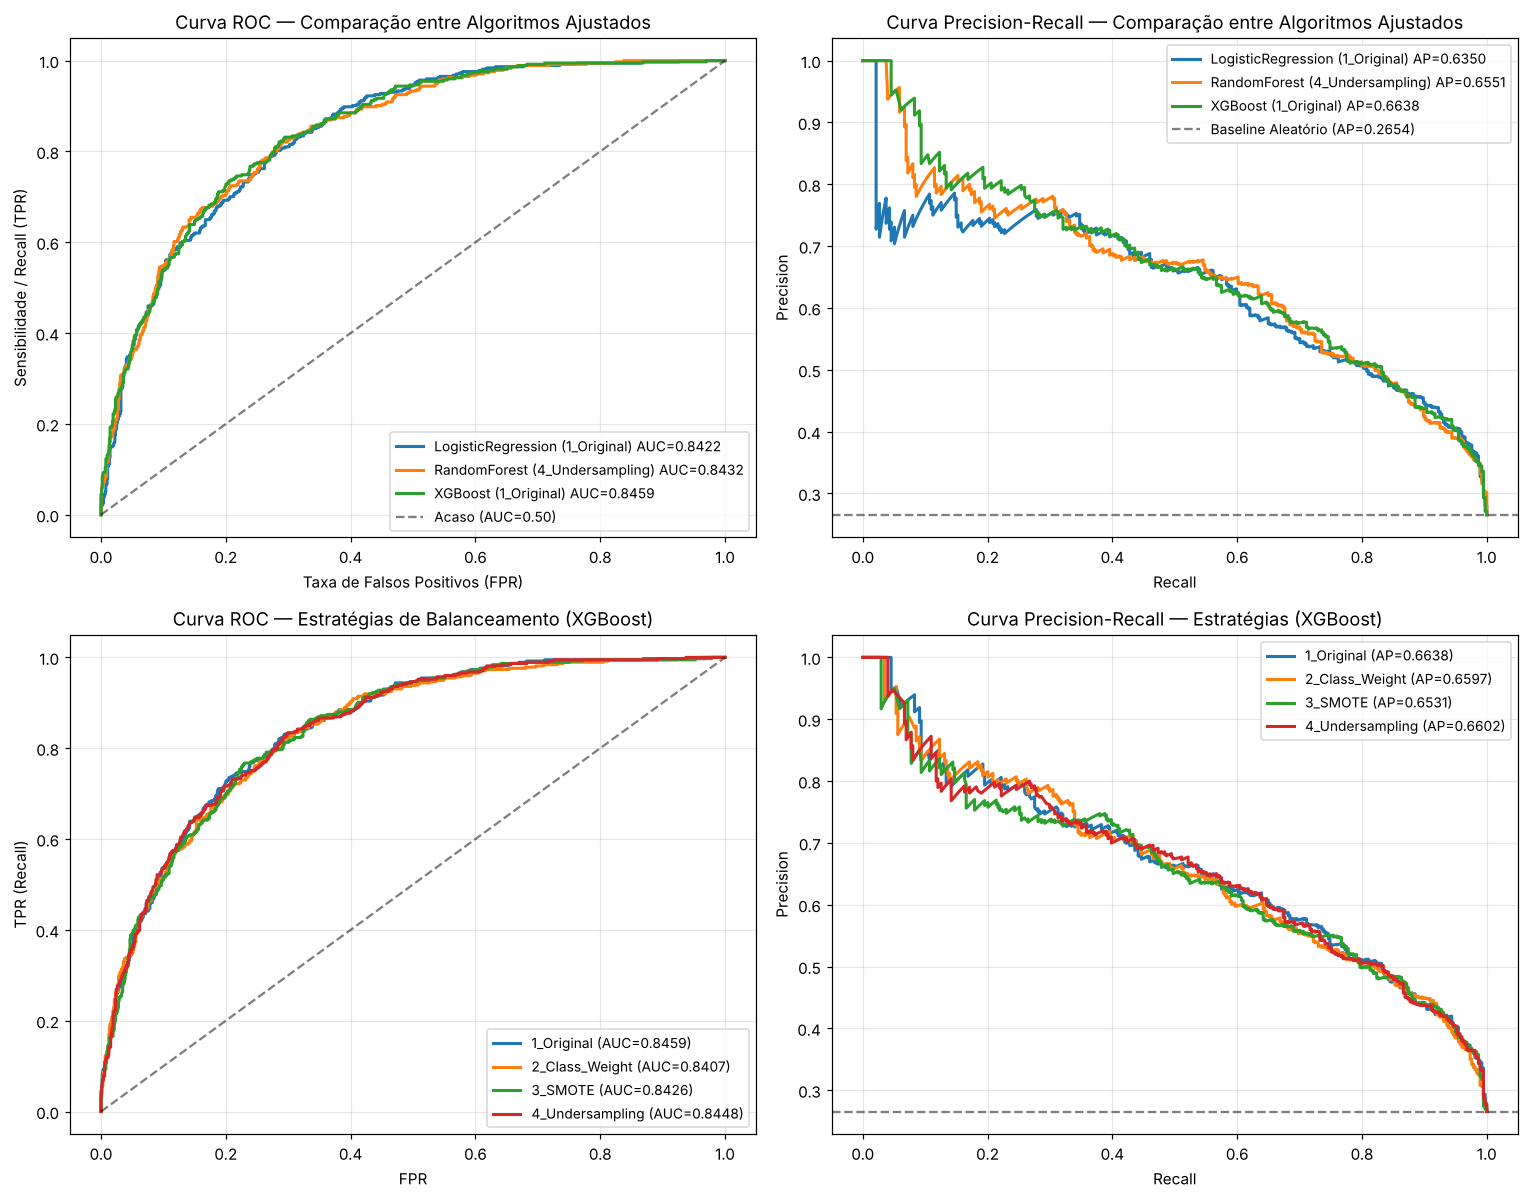

In [13]:
# 6.2 Curvas ROC & PR: (A) Melhor de cada algoritmo vs. (B) 4 estratégias no algoritmo campeão
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
prevalencia_teste = y_test.mean()

# Linha superior: comparação entre algoritmos
for mod_nome in ["LogisticRegression", "RandomForest", "XGBoost"]:
    sub = df_resultados[df_resultados["Modelo"] == mod_nome].iloc[0]
    y_p = melhores_pipelines[(sub["Estrategia"], mod_nome)].predict_proba(X_te_mod)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_p)
    prec_c, rec_c, _ = precision_recall_curve(y_test, y_p)
    axes[0, 0].plot(fpr, tpr, lw=2, label=f"{mod_nome} ({sub['Estrategia']}) AUC={sub['Test_ROC_AUC']:.4f}")
    axes[0, 1].plot(rec_c, prec_c, lw=2, label=f"{mod_nome} ({sub['Estrategia']}) AP={sub['Test_AP']:.4f}")

axes[0, 0].plot([0, 1], [0, 1], "k--", alpha=0.5, label="Acaso (AUC=0.50)")
axes[0, 0].set_title("Curva ROC — Comparação entre Algoritmos Ajustados")
axes[0, 0].set_xlabel("Taxa de Falsos Positivos (FPR)")
axes[0, 0].set_ylabel("Sensibilidade / Recall (TPR)")
axes[0, 0].legend(fontsize=9)
axes[0, 0].grid(alpha=0.3)

axes[0, 1].axhline(prevalencia_teste, color="k", ls="--", alpha=0.5, label=f"Baseline Aleatório (AP={prevalencia_teste:.4f})")
axes[0, 1].set_title("Curva Precision-Recall — Comparação entre Algoritmos Ajustados")
axes[0, 1].set_xlabel("Recall")
axes[0, 1].set_ylabel("Precision")
axes[0, 1].legend(fontsize=9)
axes[0, 1].grid(alpha=0.3)

# Linha inferior: comparação entre estratégias de balanceamento no melhor algoritmo
for est_nome in estrategias.keys():
    sub_e = df_resultados[(df_resultados["Modelo"] == best_mod_ap) & (df_resultados["Estrategia"] == est_nome)].iloc[0]
    y_p = melhores_pipelines[(est_nome, best_mod_ap)].predict_proba(X_te_mod)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_p)
    prec_c, rec_c, _ = precision_recall_curve(y_test, y_p)
    axes[1, 0].plot(fpr, tpr, lw=2, label=f"{est_nome} (AUC={sub_e['Test_ROC_AUC']:.4f})")
    axes[1, 1].plot(rec_c, prec_c, lw=2, label=f"{est_nome} (AP={sub_e['Test_AP']:.4f})")

axes[1, 0].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[1, 0].set_title(f"Curva ROC — Estratégias de Balanceamento ({best_mod_ap})")
axes[1, 0].set_xlabel("FPR")
axes[1, 0].set_ylabel("TPR (Recall)")
axes[1, 0].legend(fontsize=9)
axes[1, 0].grid(alpha=0.3)

axes[1, 1].axhline(prevalencia_teste, color="k", ls="--", alpha=0.5)
axes[1, 1].set_title(f"Curva Precision-Recall — Estratégias ({best_mod_ap})")
axes[1, 1].set_xlabel("Recall")
axes[1, 1].set_ylabel("Precision")
axes[1, 1].legend(fontsize=9)
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Variação do Limiar de Decisão — XGBoost (1_Original):


,Limiar,Clientes_Acionados,Pct_Base_Acionada,Precision,Recall,F1
0,0.15,774,54.93,0.4367,0.9037,0.5889
1,0.20,680,48.26,0.4721,0.8583,0.6091
2,0.25,613,43.51,0.5057,0.8289,0.6282
3,0.30,552,39.18,0.5254,0.7754,0.6263
4,0.35,492,34.92,0.5610,0.7380,0.6374
5,0.40,415,29.45,0.5928,0.6578,0.6236
6,0.45,353,25.05,0.6261,0.5909,0.6080
7,0.50,292,20.72,0.6610,0.5160,0.5796
8,0.55,235,16.68,0.6936,0.4358,0.5353
9,0.60,177,12.56,0.7288,0.3449,0.4682


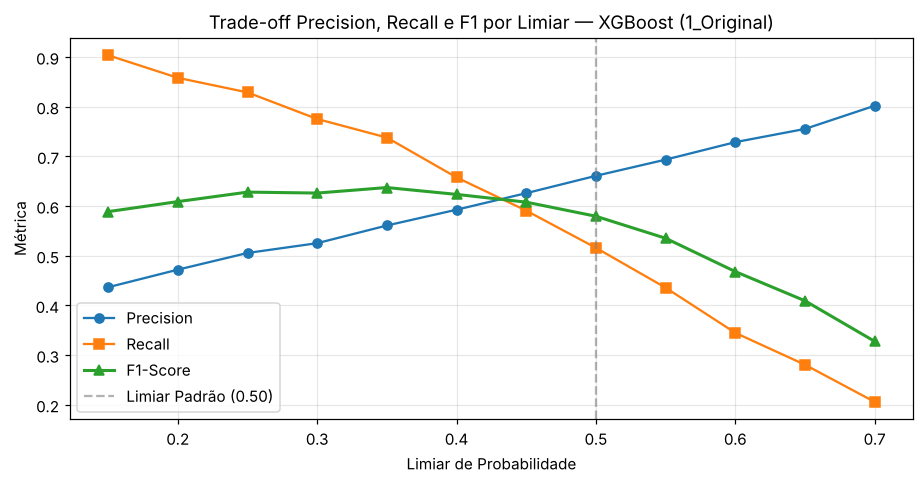

In [14]:
# 6.3 Análise do Limiar de Decisão no modelo campeão com probabilidades calibradas (1_Original)
pipe_orig_campeao = melhores_pipelines[("1_Original", best_mod_ap)]
y_prob_orig_campeao = pipe_orig_campeao.predict_proba(X_te_mod)[:, 1]

limiares = np.round(np.arange(0.15, 0.75, 0.05), 2)
linhas_limiar = []
for th in limiares:
    yp = (y_prob_orig_campeao >= th).astype(int)
    linhas_limiar.append({
        "Limiar": float(th),
        "Clientes_Acionados": int(yp.sum()),
        "Pct_Base_Acionada": round(yp.mean() * 100, 2),
        "Precision": round(precision_score(y_test, yp, zero_division=0), 4),
        "Recall": round(recall_score(y_test, yp), 4),
        "F1": round(f1_score(y_test, yp), 4),
    })

df_limiares = pd.DataFrame(linhas_limiar)
print(f"Variação do Limiar de Decisão — {best_mod_ap} (1_Original):")
display(df_limiares)

plt.figure(figsize=(8.5, 4.5))
plt.plot(df_limiares["Limiar"], df_limiares["Precision"], "o-", label="Precision")
plt.plot(df_limiares["Limiar"], df_limiares["Recall"], "s-", label="Recall")
plt.plot(df_limiares["Limiar"], df_limiares["F1"], "^-", lw=2, label="F1-Score")
plt.axvline(0.50, color="gray", ls="--", alpha=0.6, label="Limiar Padrão (0.50)")
plt.title(f"Trade-off Precision, Recall e F1 por Limiar — {best_mod_ap} (1_Original)")
plt.xlabel("Limiar de Probabilidade")
plt.ylabel("Métrica")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
# 6.3b Escolha do limiar SEM olhar o conjunto de teste: previsões out-of-fold no treino
from sklearn.model_selection import cross_val_predict

pipe_limiar = clone(melhores_pipelines[("1_Original", best_mod_ap)])
oof_prob = cross_val_predict(pipe_limiar, X_tr_mod, y_train, cv=cv, method="predict_proba")[:, 1]

grid_lim = np.round(np.arange(0.15, 0.75, 0.05), 2)
oof_f1 = [f1_score(y_train, (oof_prob >= t).astype(int)) for t in grid_lim]
limiar_cv = float(grid_lim[int(np.argmax(oof_f1))])

yp_cv = (y_prob_orig_campeao >= limiar_cv).astype(int)
yp_50 = (y_prob_orig_campeao >= 0.50).astype(int)
tab_lim_cv = pd.DataFrame({
    "Limiar": [0.50, limiar_cv],
    "Origem do limiar": ["padrão", "maximiza F1 em CV (treino)"],
    "Precision": [precision_score(y_test, yp_50), precision_score(y_test, yp_cv)],
    "Recall": [recall_score(y_test, yp_50), recall_score(y_test, yp_cv)],
    "F1": [f1_score(y_test, yp_50), f1_score(y_test, yp_cv)],
    "Clientes_Acionados": [int(yp_50.sum()), int(yp_cv.sum())],
})
print(f"Limiar escolhido apenas com dados de treino (out-of-fold): {limiar_cv:.2f}")
print("Desempenho no TESTE com esse limiar vs. o limiar padrão:")
display(tab_lim_cv.round(4))

Limiar escolhido apenas com dados de treino (out-of-fold): 0.30
Desempenho no TESTE com esse limiar vs. o limiar padrão:


,Limiar,Origem do limiar,Precision,Recall,F1,Clientes_Acionados
0,0.5,padrão,0.6610,0.5160,0.5796,292
1,0.3,maximiza F1 em CV (treino),0.5254,0.7754,0.6263,552


### Leitura do efeito do limiar de decisão

- Com o XGBoost sem reamostragem, mover o limiar percorre o mesmo ranking de clientes: em 0,15 a sensibilidade é 0,904 com precisão 0,437 (774 clientes acionados, 54,9% da base); em 0,50, sensibilidade 0,516 e precisão 0,661 (292 clientes); em 0,70, sensibilidade 0,206 e precisão 0,802 (96 clientes).
- O F1 máximo na grade ocorre em 0,35 (F1 = 0,6374), mas **escolher o limiar olhando o teste é otimista**. Escolhendo o limiar apenas com previsões out-of-fold no treino (6.3b), o valor é **0,30**, e no teste isso dá F1 = 0,6263 (sensibilidade 0,7754; precisão 0,5254; 552 clientes acionados), contra F1 = 0,5796 no limiar padrão. Esse F1 é praticamente igual ao melhor F1 obtido por qualquer estratégia de reamostragem no limiar 0,50 (0,6270, Random Forest com ponderação): **ajustar o limiar produz o mesmo efeito sem alterar a distribuição de treino**.
- O limiar adequado depende do custo de cada erro: o F1 trata falsos alarmes e cancelamentos perdidos como igualmente graves. Se contatar um cliente for caro, convém um limiar mais alto; se perder um cliente custar muito mais que a oferta de retenção, um limiar mais baixo.

In [16]:
# 6.4 Simulação de Campanha Top 10% (Questão 5)
def simular_top_k(y_true: pd.Series, probs: np.ndarray, fracao: float, nome: str) -> dict:
    df_rank = pd.DataFrame({"y_true": y_true.values, "prob": probs}).sort_values("prob", ascending=False)
    n_k = int(round(len(df_rank) * fracao))
    top_k = df_rank.head(n_k)
    churns_tot = int(df_rank["y_true"].sum())
    churns_cap = int(top_k["y_true"].sum())
    rec_k = churns_cap / churns_tot
    prec_k = churns_cap / n_k
    lift_k = prec_k / df_rank["y_true"].mean()
    return {
        "Modelo": nome,
        "Clientes_Contatados_10%": n_k,
        "Churns_Capturados": churns_cap,
        "Total_Churns_Teste": churns_tot,
        "Recall@10%_(%)": round(rec_k * 100, 2),
        "Precision@10%_(%)": round(prec_k * 100, 2),
        "Lift_vs_Acaso": round(lift_k, 2),
    }

y_prob_lr_orig = melhores_pipelines[("1_Original", "LogisticRegression")].predict_proba(X_te_mod)[:, 1]
y_prob_rf_orig = melhores_pipelines[("1_Original", "RandomForest")].predict_proba(X_te_mod)[:, 1]
y_prob_xgb_orig = melhores_pipelines[("1_Original", "XGBoost")].predict_proba(X_te_mod)[:, 1]
y_prob_best_ap = best_pipe_ap.predict_proba(X_te_mod)[:, 1]

linhas_top10 = [
    simular_top_k(y_test, y_prob_lr_orig, 0.10, "LogisticRegression (1_Original)"),
    simular_top_k(y_test, y_prob_rf_orig, 0.10, "RandomForest (1_Original)"),
    simular_top_k(y_test, y_prob_xgb_orig, 0.10, "XGBoost (1_Original)"),
]
if best_est_ap != "1_Original":  # evita linha duplicada quando o campeão já é o 1_Original
    linhas_top10.append(simular_top_k(y_test, y_prob_best_ap, 0.10, f"{best_mod_ap} ({best_est_ap})"))
top10_df = pd.DataFrame(linhas_top10)
print("\nSimulação de Campanha Top 10% Maior Risco (Conjunto de Teste):")
display(top10_df)


Simulação de Campanha Top 10% Maior Risco (Conjunto de Teste):


,Modelo,Clientes_Contatados_10%,Churns_Capturados,Total_Churns_Teste,Recall@10%_(%),Precision@10%_(%),Lift_vs_Acaso
0,LogisticRegression (1_Original),141,105,374,28.07,74.47,2.81
1,RandomForest (1_Original),141,104,374,27.81,73.76,2.78
2,XGBoost (1_Original),141,106,374,28.34,75.18,2.83


### Resposta à questão do top 10%

Contatando apenas os 10% de clientes com maior risco previsto (**141 dos 1.409** do conjunto de teste), o XGBoost sem reamostragem identifica **106 dos 374 cancelamentos = 28,34%**. Nesse grupo, 75,18% dos clientes realmente cancelaram, um *lift* de **2,83×** em relação à taxa de base (uma seleção aleatória de 10% capturaria cerca de 10% dos cancelamentos, aproximadamente 37). A Regressão Logística (105; 28,07%) e o Random Forest (104; 27,81%) são praticamente equivalentes. Como 141 clientes só poderiam cobrir no máximo 141 dos 374 cancelamentos (37,7%), o ranking atinge cerca de três quartos do máximo possível para esse tamanho de campanha. Esta é uma estimativa de um único conjunto de teste.

## 7. Interpretação de Variáveis, Consistência entre Modelos e Discussão Crítica

Comparar a importância das variáveis entre três arquiteturas distintas (`LogisticRegression` linear, `RandomForest` via *bagging* e `XGBoost` via *gradient boosting*) permite separar fatores estruturais robustos de artefatos específicos de um algoritmo (como inversões de sinal causadas por multicolinearidade entre `tenure`, `MonthlyCharges` e `TotalCharges` em modelos lineares).

Consistência de Importância Relativa (%) entre os 3 Modelos (Top 12 atributos):


,LR_Coef_Direcional,LR_Imp_%,RF_Imp_%,XGB_Imp_%,Media_Imp_%
InternetService_Fiber optic,1.1823,11.26,10.29,19.500000,13.68
Contract_Two year,-1.3264,12.64,9.26,17.360001,13.09
tenure,-1.2505,11.91,19.94,5.410000,12.42
Contract_One year,-0.6866,6.54,4.34,22.459999,11.11
PaymentMethod_Electronic check,0.3839,3.66,8.90,7.170000,6.58
TotalCharges,0.5231,4.98,12.95,1.160000,6.36
MonthlyCharges,-0.4708,4.49,6.98,0.830000,4.10
OnlineSecurity_Yes,-0.3496,3.33,4.15,3.060000,3.51
InternetService_No,-0.1734,1.65,1.36,6.980000,3.33
PaperlessBilling_Yes,0.3713,3.54,1.55,3.370000,2.82


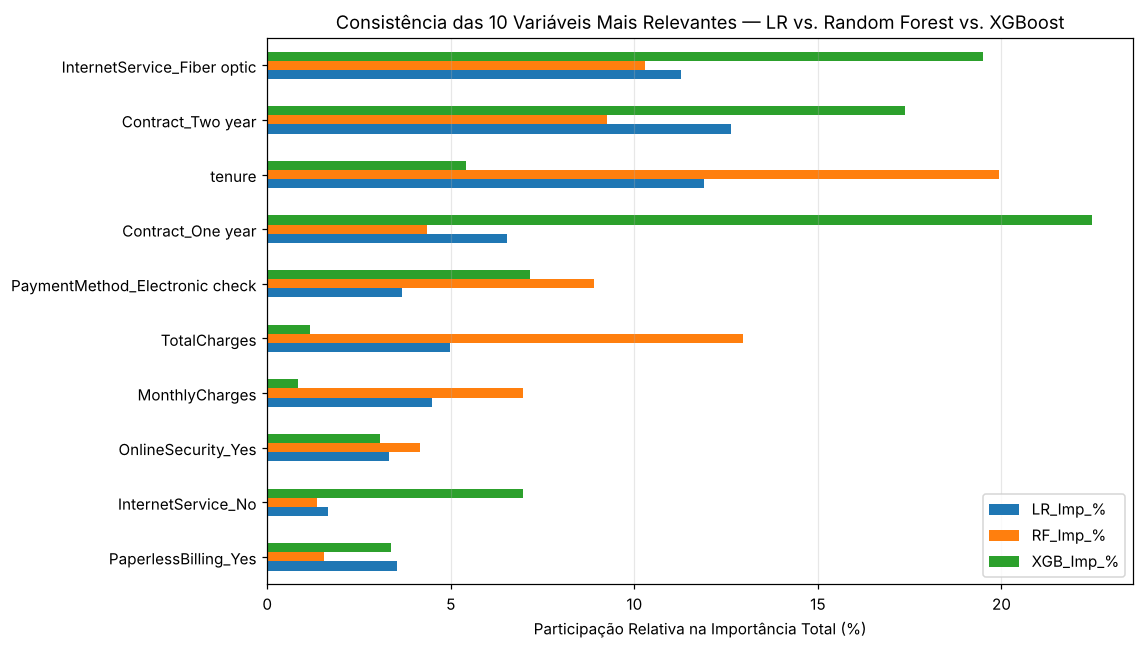

SÍNTESE QUANTITATIVA AUTOMÁTICA PARA AS QUESTÕES DO PROJETO
1) Top 5 atributos consensuais (média %): ['InternetService_Fiber optic', 'Contract_Two year', 'tenure', 'Contract_One year', 'PaymentMethod_Electronic check']
2) Melhor ranking global (Test_AP):     XGBoost | 1_Original (AP=0.6638, AUC=0.8459)
3) Melhor F1 no limiar padrão 0.50:     RandomForest | 2_Class_Weight (F1=0.6270, Recall=0.8182)
4) Melhor F1 por ajuste de limiar (XGBoost 1_Original): limiar=0.35 -> F1=0.6374, Recall=0.7380, Prec=0.5610
5) Captura no Top 10% (XGBoost (1_Original)): 106/374 churns (28.34% | Lift=2.83x)

Sinal do coeficiente (LR, padronizado) vs. correlação marginal — variáveis numéricas:


,LR_Coef_Direcional,RF_Imp_%,XGB_Imp_%,Corr_marginal_com_Churn
tenure,-1.2505,19.94,5.41,-0.3522
MonthlyCharges,-0.4708,6.98,0.83,0.1934
TotalCharges,0.5231,12.95,1.16,-0.1983


In [17]:
def extrair_importancias_norm(pipe_treinado: ImbPipeline, modelo_nome: str) -> pd.Series:
    nomes = pipe_treinado.named_steps["prep"].get_feature_names_out()
    clf = pipe_treinado.named_steps["clf"]
    vals = np.abs(clf.coef_[0]) if modelo_nome == "LogisticRegression" else clf.feature_importances_
    s = pd.Series(vals, index=nomes)
    return (s / s.sum()) * 100.0

imp_lr = extrair_importancias_norm(melhores_pipelines[("1_Original", "LogisticRegression")], "LogisticRegression")
imp_rf = extrair_importancias_norm(melhores_pipelines[("1_Original", "RandomForest")], "RandomForest")
imp_xgb = extrair_importancias_norm(melhores_pipelines[("1_Original", "XGBoost")], "XGBoost")

nomes_feat = melhores_pipelines[("1_Original", "LogisticRegression")].named_steps["prep"].get_feature_names_out()
coefs_lr = pd.Series(
    melhores_pipelines[("1_Original", "LogisticRegression")].named_steps["clf"].coef_[0],
    index=nomes_feat,
)

df_imp = pd.DataFrame({
    "LR_Coef_Direcional": coefs_lr.round(4),
    "LR_Imp_%": imp_lr.round(2),
    "RF_Imp_%": imp_rf.round(2),
    "XGB_Imp_%": imp_xgb.round(2),
})
df_imp["Media_Imp_%"] = df_imp[["LR_Imp_%", "RF_Imp_%", "XGB_Imp_%"]].mean(axis=1).round(2)
df_imp = df_imp.sort_values("Media_Imp_%", ascending=False)

print("Consistência de Importância Relativa (%) entre os 3 Modelos (Top 12 atributos):")
display(df_imp.head(12))

top10_plot = df_imp.head(10).sort_values("Media_Imp_%", ascending=True)
top10_plot[["LR_Imp_%", "RF_Imp_%", "XGB_Imp_%"]].plot(kind="barh", figsize=(10.5, 6))
plt.title("Consistência das 10 Variáveis Mais Relevantes — LR vs. Random Forest vs. XGBoost")
plt.xlabel("Participação Relativa na Importância Total (%)")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

# Relatório quantitativo dinâmico para subsidiar as 6 questões norteadoras
limiar_max_f1 = df_limiares.sort_values("F1", ascending=False).iloc[0]
melhor_top10 = top10_df.sort_values("Recall@10%_(%)", ascending=False).iloc[0]
print("=" * 72)
print("SÍNTESE QUANTITATIVA AUTOMÁTICA PARA AS QUESTÕES DO PROJETO")
print("=" * 72)
print(f"1) Top 5 atributos consensuais (média %): {list(df_imp.head(5).index)}")
print(f"2) Melhor ranking global (Test_AP):     {best_mod_ap} | {best_est_ap} (AP={best_row_ap['Test_AP']:.4f}, AUC={best_row_ap['Test_ROC_AUC']:.4f})")
print(f"3) Melhor F1 no limiar padrão 0.50:     {best_mod_f1} | {best_est_f1} (F1={best_row_f1['Test_F1']:.4f}, Recall={best_row_f1['Test_Recall']:.4f})")
print(f"4) Melhor F1 por ajuste de limiar ({best_mod_ap} 1_Original): limiar={limiar_max_f1['Limiar']:.2f} -> F1={limiar_max_f1['F1']:.4f}, Recall={limiar_max_f1['Recall']:.4f}, Prec={limiar_max_f1['Precision']:.4f}")
print(f"5) Captura no Top 10% ({melhor_top10['Modelo']}): {melhor_top10['Churns_Capturados']}/{melhor_top10['Total_Churns_Teste']} churns ({melhor_top10['Recall@10%_(%)']:.2f}% | Lift={melhor_top10['Lift_vs_Acaso']:.2f}x)")

# Sinais dos coeficientes da LR vs. correlação marginal com Churn (efeito da multicolinearidade)
corr_marg = df[["tenure", "MonthlyCharges", "TotalCharges", "Churn_Binario"]].corr()["Churn_Binario"].drop("Churn_Binario")
comparacao_sinais = df_imp.loc[["tenure", "MonthlyCharges", "TotalCharges"], ["LR_Coef_Direcional", "RF_Imp_%", "XGB_Imp_%"]].copy()
comparacao_sinais["Corr_marginal_com_Churn"] = corr_marg.round(4)
print("\nSinal do coeficiente (LR, padronizado) vs. correlação marginal — variáveis numéricas:")
display(comparacao_sinais)

### Leitura das importâncias das variáveis

- **Consenso entre os três modelos (média das importâncias normalizadas):** `InternetService_Fiber optic` (13,68%), `Contract_Two year` (13,09%), `tenure` (12,42%), `Contract_One year` (11,11%) e `PaymentMethod_Electronic check` (6,58%). Como a categoria de referência é o contrato mensal, os coeficientes negativos de `Contract_Two year` (-1,33) e `Contract_One year` (-0,69) indicam que contratos mais longos se associam a menor risco (ou, equivalentemente, o contrato mensal a maior). A fibra óptica tem coeficiente positivo (+1,18) na Regressão Logística e peso alto nos três modelos.
- **A consistência é parcial:** os mesmos grupos de variáveis (contrato, fibra, tempo de casa, cheque eletrônico) aparecem no topo, mas o peso atribuído varia muito: `tenure` vale 19,94% no Random Forest e 5,41% no XGBoost, `TotalCharges` 12,95% contra 1,16%, e o XGBoost concentra importância nos contratos (17,36% e 22,46%). Importâncias de árvores e |coeficientes| padronizados **não são diretamente comparáveis**; vale comparar sobretudo o ranking, não os valores.
- **Sinais invertidos pela multicolinearidade:** na Regressão Logística, `TotalCharges` tem coeficiente **positivo** (+0,52), embora sua correlação marginal com o churn seja negativa (-0,1983), e `MonthlyCharges` tem coeficiente **negativo** (-0,47), embora sua correlação marginal seja positiva (+0,1934). Isso decorre da colinearidade com `tenure` e do controle pelos serviços contratados (a mensalidade é em grande parte função dos serviços, em especial da fibra). Por isso os coeficientes individuais dessas três variáveis **não devem ser interpretados isoladamente**.

## 8. Discussão Crítica e Respostas às Questões Norteadoras

*Todos os números citados vêm das saídas executadas neste notebook (`RANDOM_STATE = 42`; teste com 1.409 clientes, dos quais 374 cancelaram).*

### 1. Quais características estão associadas a maiores taxas de cancelamento?

A taxa global é de 26,54%. As maiores taxas aparecem em: contrato mensal (42,71%, n = 3.875, contra 11,27% no anual e 2,83% no bienal); internet em fibra óptica (41,89% contra 18,96% em DSL); pagamento por cheque eletrônico (45,29% contra 15% a 19% nas demais formas); ausência de `OnlineSecurity` (41,77% contra 14,61%) e de `TechSupport` (41,64% contra 15,17%); clientes idosos (41,68% contra 23,61%); sem parceiro ou sem dependentes; tempo de permanência curto (mediana de 10 meses entre quem cancela contra 38 entre quem fica). `gender`, `PhoneService` e streaming mostram pouca ou nenhuma associação. Nos três modelos, as variáveis de maior importância média foram fibra óptica, contrato bienal, `tenure`, contrato anual e cheque eletrônico (Seção 7). Essas são associações observacionais, não causas.

### 2. Como tempo de permanência, tipo de contrato e valores cobrados se relacionam com o cancelamento?

- **Tempo × contrato:** no contrato mensal, o churn cai com o tempo de casa, de 55,20% (0 a 6 meses, n = 1.413) para 26,02% (49 a 72 meses); 95,4% dos clientes com até 6 meses estão nesse contrato. No contrato anual o churn é de 8% a 13% em todas as faixas, e no bienal fica próximo de zero (0% até 24 meses, 2,19% a 3,33% depois; as células de contratos longos com pouco tempo de casa têm poucos clientes, n entre 29 e 90).
- **Valores cobrados:** o churn aumenta com a mensalidade dentro de cada contrato (mensal: 25,03% no 1º quartil contra 52,18% no 4º; anual: 3,05% contra 20,85%; bienal: 0,78% contra 7,01%), mas o tipo de contrato pesa mais: um cliente do contrato mensal de menor mensalidade (25,03%) cancela mais do que um do contrato bienal de maior mensalidade (7,01%). `TotalCharges` reflete essencialmente `tenure × MonthlyCharges` (r = 0,8262); sua correlação negativa com o churn (-0,1983) vem do tempo de casa, e na Regressão Logística o sinal se inverte (+0,52) por multicolinearidade (VIF = 9,68), de modo que não indica que pagar mais acumulado cause mais cancelamento.

### 3. Qual classificador apresenta os melhores resultados? A conclusão depende da métrica?

**Depende.** Em ranking (Average Precision e ROC-AUC), o melhor foi o XGBoost sem reamostragem (AP = 0,6638; AUC = 0,8459), que também liderou em validação cruzada (AP = 0,6674). Mas a margem é pequena: em CV os melhores AP de cada algoritmo são 0,6674, 0,6615 e 0,6615 (diferença menor que a variação entre folds, cerca de 0,015), as 12 combinações têm ROC-AUC entre 0,840 e 0,846, e, com um único conjunto de teste de 374 cancelamentos, **não é possível afirmar que um algoritmo seja claramente superior**. No limiar 0,50, a maior precisão é do Random Forest sem reamostragem (0,6667; XGBoost 0,6610 e Regressão Logística 0,6604), enquanto a maior sensibilidade (0,8182) e o maior F1 (0,6270) são do Random Forest com ponderação de classes. A Regressão Logística fica competitiva e é a mais fácil de interpretar.

### 4. O tratamento do desbalanceamento melhora o desempenho?

- **Melhora sensibilidade e F1 no limiar 0,50, mas não o ranking.** Ponderação, subamostragem e SMOTE aumentam a sensibilidade em 0,16 a 0,38 e o F1 em 0,01 a 0,10, ao custo de queda de precisão de 0,09 a 0,16. O AP e o ROC-AUC, porém, não melhoram: o AP varia de -0,011 a +0,0005, e o SMOTE o reduz nos três algoritmos.
- **O mesmo efeito vem do ajuste do limiar.** Com o XGBoost sem reamostragem, o limiar escolhido em validação cruzada (0,30) leva a F1 = 0,6263 no teste (contra 0,5796 em 0,50), valor equivalente ao melhor F1 obtido com reamostragem em 0,50 (0,6270). Ou seja, os métodos de balanceamento deslocaram o ponto de operação, sem melhorar a separação entre as classes.
- **Subamostragem (undersampling):** descarta informação da classe majoritária (cerca de 2.644 dos 4.139 clientes que permaneceram no treino completo, aproximadamente 64%), o que aumenta a variância do modelo; aqui ela não trouxe ganho de ranking (ΔAP entre -0,004 e +0,0005). Tem a vantagem de reduzir o tempo de treino.
- **Sobreamostragem (SMOTE):** cria exemplos sintéticos por interpolação, o que, com colunas binárias (*one-hot*), gera valores intermediários que não existem na realidade e aumenta o risco de sobreajuste a ruído local da classe minoritária; coerentemente, foi a estratégia que mais reduziu o AP (-0,005 a -0,011). Foi aplicada somente dentro dos folds de treino.
- Ponderação e reamostragem também distorcem as probabilidades previstas, que deixam de representar o risco real do cliente.

### 5. Se a empresa pudesse contatar apenas 10% dos clientes, qual proporção dos cancelamentos seria identificada?

Contatando os 141 clientes (10% do teste) de maior risco previsto, o XGBoost sem reamostragem identifica **106 dos 374 cancelamentos, isto é, 28,34%**, com precisão de 75,18% no grupo e *lift* de 2,83× (uma seleção aleatória capturaria cerca de 10%). Regressão Logística (28,07%) e Random Forest (27,81%) ficam praticamente iguais. Como esse tamanho de campanha só poderia cobrir no máximo 37,7% dos cancelamentos, o resultado equivale a cerca de três quartos do máximo possível.

### 6. Quais resultados orientam hipóteses de retenção e por que os dados não permitem concluir que as ações reduziriam os cancelamentos?

**Hipóteses sugeridas pelos padrões:**
1. Acompanhamento reforçado dos clientes novos sem fidelidade: o grupo com até 6 meses no contrato mensal tem 55,20% de churn e reúne cerca de 20% da base (1.413 de 7.043).
2. Testar ofertas de migração do contrato mensal para anual (contratos longos têm churn de 3% a 11%).
3. Testar pacotes com `TechSupport` e `OnlineSecurity` para clientes de fibra óptica, e a migração do cheque eletrônico para débito automático ou cartão.

**Por que os dados não permitem concluir que essas ações reduziriam o cancelamento:**
- Os dados são **observacionais**: os modelos capturam associações, não efeitos causais. Clientes escolhem o contrato, o serviço e a forma de pagamento, e essa escolha pode refletir características não observadas (sensibilidade a preço, renda, concorrência na região, qualidade real do serviço) que também influenciam o cancelamento. Por exemplo, quem usa `TechSupport` pode simplesmente ser um cliente mais engajado; obrigar a troca de forma de pagamento ou de contrato não garante que o risco acompanhe a mudança.
- **Risco previsto não é o mesmo que "efeito da ação":** os clientes de maior risco podem ser justamente os que cancelariam de qualquer forma; seria preciso estimar o efeito incremental (*uplift*) da oferta.
- O conjunto é um **retrato de um mês** (cancelamento no último mês), sem informação de causa do cancelamento, de custos, nem de ações anteriores da empresa.
- Para validar causalidade, recomenda-se **experimentos randomizados (testes A/B)** com grupo de controle em grupos-piloto de alto risco, medindo a retenção real e o retorno financeiro da ação.

### Limitações do estudo

- Um único particionamento treino/teste (80/20), sem intervalos de confiança: diferenças de AP da ordem de 0,01 estão dentro da variabilidade esperada, e cerca de 374 cancelamentos no teste tornam as estimativas de sensibilidade e do top 10% imprecisas.
- Grades de hiperparâmetros pequenas (4 a 8 combinações por modelo); os limiares foram avaliados em passos de 0,05.
- As importâncias das variáveis não são comparáveis em valor absoluto entre algoritmos, e os coeficientes da Regressão Logística sofrem com a multicolinearidade entre `tenure`, `MonthlyCharges` e `TotalCharges`.
- Não houve validação temporal nem análise de calibração das probabilidades; não há matriz de custos, então a escolha do limiar ideal depende de informações de negócio que os dados não contêm.